# BERT Sentiment Analyzer
### Rick Jacoby

Assignment = build a sentiment analyzer with BERT + Hugging Face Transformers, trained on the Stanford Sentiment Treebank. Approach:

1. first build a binary (positive/negative) classifier since it's easier and sets direction
2. learn from binary to make better decisions on a 5 class version
3. compare 

**update** First attempted solution ran VERY fast on my 6GB GPU. I want to explore if a bigger pretrained model will improve results. Adding 2nd experiment as a redo of both (binary and 5 class) with BERT-large plus a learning- rate search. The original bert-base run stays... just adding a more robust attempt for compare.

+ SMS alert via twillio for long running builds 


In [ ]:
# imports + reproducibility + paths + run config, plus a little timer class used everywhere below
from pathlib import Path
import contextlib
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from IPython.display import display
from tqdm.auto import tqdm

# this machine can't verify SSL certs when hitting the HF hub without this. + Truststore fix
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

import torch
from torch import nn
from nltk.tree import Tree
from nltk.tokenize.treebank import TreebankWordDetokenizer
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    pipeline,
)
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import chi2
from sklearn.utils.class_weight import compute_class_weight

SEED = 574  
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = PROJECT_ROOT / "data" / "raw" / "sst"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "assignment3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

#######################################
# SMOKE TEST SWITCH to run whole book lite to check for bugs 
######################
SMOKE_TEST = os.getenv("SMOKE_TEST", "1") == "0"  # 1 = True (0 false for full run

MODEL_NAME = "bert-base-cased"  
MAX_LENGTH = 128  # generous cap. Ref to sec 1 

if SMOKE_TEST:
    TRAIN_SUBSET, DEV_SUBSET = 200, 60
    EPOCHS_BINARY, EPOCHS_5CLASS = 1, 1
else:
    TRAIN_SUBSET, DEV_SUBSET = None, None
    EPOCHS_BINARY, EPOCHS_5CLASS = 4, 5

BATCH_SIZE_TRAIN, BATCH_SIZE_EVAL = 16, 32
FP16 = DEVICE.type == "cuda"

print(f"Device: {DEVICE}  |  Smoke test: {SMOKE_TEST}  |  Data dir: {DATA_DIR}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

assert (DATA_DIR / "train.txt").exists() and (DATA_DIR / "dev.txt").exists(), (
    f"Expected {DATA_DIR / 'train.txt'} and {DATA_DIR / 'dev.txt'}. Copy them from the "
    "assign3 homework folder into data/raw/sst/ before running this notebook."
)


class StageTimer:
    # tracks how long each part of the notebook takes and dumps it to a csv as it goes.
    # block() is for stuff that fits in one cell, start()/stop() is for stuff that spans
    # a few cells (can't wrap a `with` around multiple cells, so this is workaround
    def __init__(self, log_path):
        self.log_path = log_path
        self.rows = []
        self._stack = []

    def _log(self, name, elapsed):
        self.rows.append({"stage": name, "elapsed_seconds": elapsed})
        pd.DataFrame(self.rows).to_csv(self.log_path, index=False)
        print(f"[{name}] done in {elapsed:.1f}s")

    def start(self, name):
        self._stack.append((name, time.perf_counter()))

    def stop(self):
        name, t0 = self._stack.pop()
        elapsed = time.perf_counter() - t0
        self._log(name, elapsed)
        return elapsed

    @contextlib.contextmanager
    def block(self, name):
        self.start(name)
        try:
            yield
        finally:
            self.stop()

    def summary(self):
        return pd.DataFrame(self.rows)


timer = StageTimer(OUTPUT_DIR / "timing_log.csv")


Device: cuda  |  Smoke test: False  |  Data dir: data\raw\sst
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


In [ ]:
# Adding SMS for long running builds 
# 

from dotenv import load_dotenv

load_dotenv(PROJECT_ROOT / ".env")

ENABLE_SMS = True  


def send_sms_notification(message):
    if not ENABLE_SMS:
        return
    sid = os.getenv("TWILIO_ACCOUNT_SID")
    token = os.getenv("TWILIO_AUTH_TOKEN")
    from_number = os.getenv("TWILIO_FROM_NUMBER")
    to_number = os.getenv("TWILIO_TO_NUMBER")
    if not all([sid, token, from_number, to_number]):
        print("twilio not in .env - skipping sms")
        return
    try:
        resp = requests.post(
            f"https://api.twilio.com/2010-04-01/Accounts/{sid}/Messages.json",
            auth=(sid, token),
            data={"From": from_number, "To": to_number, "Body": message},
            timeout=15,
        )
        resp.raise_for_status()
        print(f"texted myself: {message!r}")
    except Exception as exc:
        print(f"sms failed ({exc}) -- not a big deal, moving on")


# msg on err
def _notify_and_show_error(shell, etype, evalue, tb, tb_offset=None):
    send_sms_notification(f"BERT sentiment run hit an error: {etype.__name__}: {evalue}")
    shell.showtraceback((etype, evalue, tb), tb_offset=tb_offset)


get_ipython().set_custom_exc((Exception,), _notify_and_show_error)


## 1. Data Exploration

SST sentences are stored as full Penn-Treebank-style parenthesized parse trees where *every* phrase/subtree gets its own sentiment label 0-4 (0 = very negative, 4 = very positive), like:

```
(3 (2 (2 The) (2 Rock)) (4 (3 (2 is) ...) (2 .)))
```

Only the root label (outermost paren) actually matters for classification. It's the whole-sentence label. Sentence text gets rebuilt from the tree's leaves. Building both a 5-class view and a binary view (drop neutral) from the same parsed data here, since I build the binary model first and the 5-class one second.


In [ ]:
# parsing helpers
### PTB tree root label, readable sentence)

PTB_UNESCAPE = {
    "-LRB-": "(", "-RRB-": ")", "-LSB-": "[", "-RSB-": "]", "-LCB-": "{", "-RCB-": "}",
}
_detok = TreebankWordDetokenizer()


def leaves_to_sentence(leaves):
    tokens = [PTB_UNESCAPE.get(tok, tok).replace("\\/", "/").replace("\\*", "*") for tok in leaves]
    return _detok.detokenize(tokens)


def load_sst_file(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            tree = Tree.fromstring(line)
            leaves = tree.leaves()
            rows.append({
                "label_5class": int(tree.label()),
                "sentence": leaves_to_sentence(leaves),
                "n_tokens": len(leaves),
            })
    return pd.DataFrame(rows)


In [ ]:
# build train/dev DataFrames
## both label views at once

with timer.block("data_parsing"):
    train_df = load_sst_file(DATA_DIR / "train.txt")
    dev_df = load_sst_file(DATA_DIR / "dev.txt")

LABEL5_NAMES = {0: "very negative", 1: "negative", 2: "neutral", 3: "positive", 4: "very positive"}
for df in (train_df, dev_df):
    df["label_5_name"] = df["label_5class"].map(LABEL5_NAMES)


def to_binary(label5):
    if label5 == 2:
        return np.nan
    return 0 if label5 in (0, 1) else 1


for df in (train_df, dev_df):
    df["label_binary"] = df["label_5class"].map(to_binary)
    df["is_neutral"] = df["label_5class"].eq(2)

assert len(train_df) == 8544 and len(dev_df) == 1101, "these split sizes don't match the SST paper, something's off"
print(f"train: {len(train_df)} sentences  |  dev: {len(dev_df)} sentences")
display(train_df.head())


[data_parsing] done in 1.7s
train: 8544 sentences  |  dev: 1101 sentences


,label_5class,sentence,n_tokens,label_5_name,label_binary,is_neutral
0,3,The Rock is destined to be the 21st Century's ...,36,positive,1.0,False
1,4,"The gorgeously elaborate continuation of ""The ...",37,very positive,1.0,False
2,3,Singer/composer Bryan Adams contributes a slew...,39,positive,1.0,False
3,2,You'd think by now America would have had enou...,19,neutral,NaN,True
4,3,Yet the act is still charming here.,8,positive,1.0,False


### 5-class label scheme (raw SST labels)

,train,dev
label_5_name,,
very negative,12.8%,12.6%
negative,26.0%,26.2%
neutral,19.0%,20.8%
positive,27.2%,25.3%
very positive,15.1%,15.0%


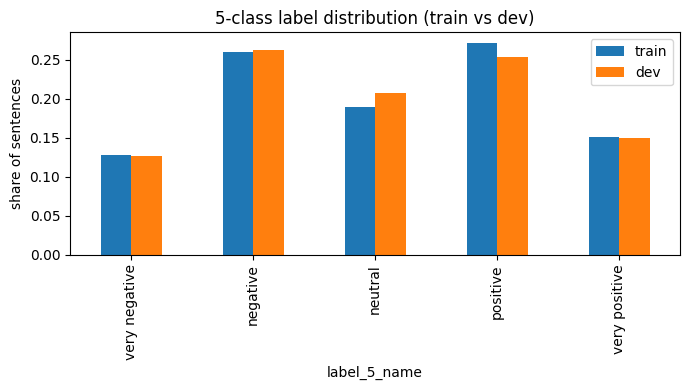

In [ ]:
# PLOT 5 class distribution on train vs dev

fig, ax = plt.subplots(figsize=(7, 4))
dist5 = pd.DataFrame({
    "train": train_df["label_5_name"].value_counts(normalize=True).reindex(LABEL5_NAMES.values()),
    "dev": dev_df["label_5_name"].value_counts(normalize=True).reindex(LABEL5_NAMES.values()),
})
display((dist5 * 100).round(1).astype(str) + "%")
dist5.plot(kind="bar", ax=ax)
ax.set_ylabel("share of sentences")
ax.set_title("5-class label distribution (train vs dev)")
plt.tight_layout()
plt.show()


### Binary label scheme (drop neutral, SST-2 style)

dropping neutral: 1624 / 8544 train, 229 / 1101 dev


,train,dev
label_binary,,
positive,52.2%,50.9%
negative,47.8%,49.1%


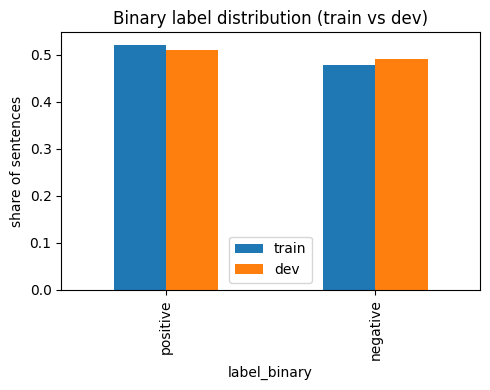

In [ ]:
# binary dist after drop neutral sentences

n_neutral_train = int(train_df["is_neutral"].sum())
n_neutral_dev = int(dev_df["is_neutral"].sum())
print(f"dropping neutral: {n_neutral_train} / {len(train_df)} train, "
      f"{n_neutral_dev} / {len(dev_df)} dev")

binary_names = {0: "negative", 1: "positive"}
dist_bin = pd.DataFrame({
    "train": train_df["label_binary"].dropna().map(binary_names).value_counts(normalize=True),
    "dev": dev_df["label_binary"].dropna().map(binary_names).value_counts(normalize=True),
})
display((dist_bin * 100).round(1).astype(str) + "%")
dist_bin.plot(kind="bar", figsize=(5, 4))
plt.ylabel("share of sentences")
plt.title("Binary label distribution (train vs dev)")
plt.tight_layout()
plt.show()


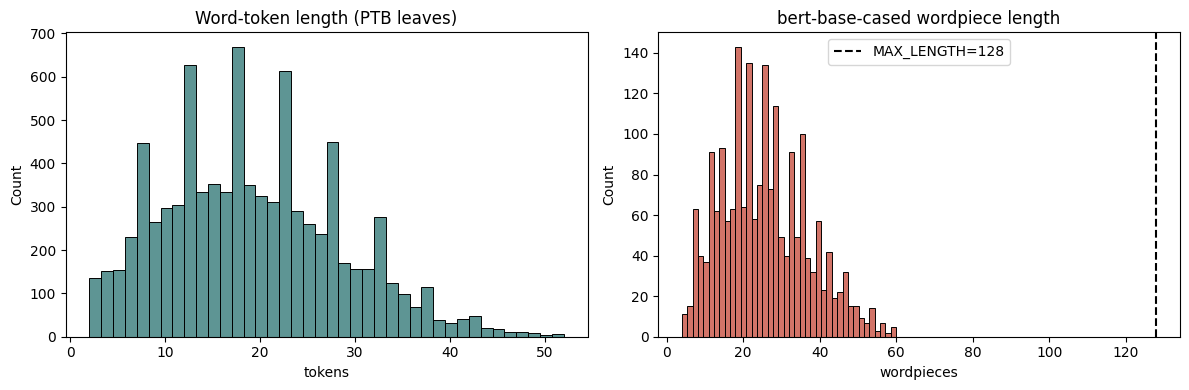

word-token length  -- p95: 35  p99: 43  max: 52
wordpiece length    -- p95: 46  p99: 54  max: 60


In [ ]:
# sentence length - word-token length (raw PTB leaves) + BERT wordpiece length

tokenizer_preview = AutoTokenizer.from_pretrained(MODEL_NAME)
sample = train_df["sentence"].sample(2000, random_state=SEED)
wordpiece_lens = np.array([len(tokenizer_preview(s)["input_ids"]) for s in sample])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train_df["n_tokens"], bins=40, ax=axes[0], color="#287271")
axes[0].set(title="Word-token length (PTB leaves)", xlabel="tokens")

sns.histplot(wordpiece_lens, bins=40, ax=axes[1], color="#c44536")
axes[1].axvline(MAX_LENGTH, linestyle="--", color="black", label=f"MAX_LENGTH={MAX_LENGTH}")
axes[1].set(title=f"{MODEL_NAME} wordpiece length", xlabel="wordpieces")
axes[1].legend()
plt.tight_layout()
plt.show()

print("word-token length  -- p95: %d  p99: %d  max: %d" % (
    np.percentile(train_df["n_tokens"], 95), np.percentile(train_df["n_tokens"], 99), train_df["n_tokens"].max()))
print("wordpiece length    -- p95: %d  p99: %d  max: %d" % (
    np.percentile(wordpiece_lens, 95), np.percentile(wordpiece_lens, 99), wordpiece_lens.max()))


In [ ]:
# sample sentences per class for eyes on 

for label, name in LABEL5_NAMES.items():
    examples = train_df.loc[train_df["label_5class"] == label, "sentence"].sample(3, random_state=SEED)
    print(f"\n--- {name} (label {label}) ---")
    for s in examples:
        print(" *", s)



--- very negative (label 0) ---
 * A lame comedy.
 * The only thing to fear about "Fear Dot Com" is hitting your head on the theater seat in front of you when you doze off thirty minutes into the film.
 * Will probably be one of those movies barely registering a blip on the radar screen of 2002.

--- negative (label 1) ---
 * Gooding and Coburn are both Oscar winners, a fact which, as you watch them clumsily mugging their way through Snow Dogs, seems inconceivable.
 * Let's see, a haunted house, a haunted ship, what's next...Ghost Blimp?
 * What with all the blanket statements and dime-store ruminations on vanity, the worries of the rich and sudden wisdom, the film becomes a sermon for most of its running time.

--- neutral (label 2) ---
 * It is there to give them a good time.
 * Streamlined to a tight, brisk 85-minute screwball thriller, "Big Trouble" is funny, harmless and as substantial as a tub of popcorn with extra butter.
 * ... has its moments, but ultimately, its curmudgeon d

In [ ]:
# most discriminative unigrams per class (chi-squared against label_5class)

vectorizer = CountVectorizer(stop_words="english", min_df=5)
X_counts = vectorizer.fit_transform(train_df["sentence"])
chi2_scores, _ = chi2(X_counts, train_df["label_5class"])
vocab = np.array(vectorizer.get_feature_names_out())

top_words = {}
for label, name in LABEL5_NAMES.items():
    mask = (train_df["label_5class"] == label).to_numpy()
    class_counts = np.asarray(X_counts[mask].sum(axis=0)).ravel()
    score = class_counts * chi2_scores
    top_idx = np.argsort(score)[::-1][:10]
    top_words[name] = vocab[top_idx]

display(pd.DataFrame(top_words))


,very negative,negative,neutral,positive,very positive
0,bad,movie,movie,movie,best
1,movie,bad,best,film,movie
2,like,like,film,best,film
3,worst,film,like,like,performances
4,film,just,bad,love,funny
5,dull,doesn,just,bad,moving
6,just,best,doesn,funny,like
7,mess,isn,funny,performances,love
8,minutes,plot,love,just,year
9,doesn,minutes,isn,fun,performance


### Observations

**5-class:** the extreme classes (very neg / very pos) are underrepresented, ~13-15% each, vs ~26-27% for the mid-polarity classes and ~19-21% neutral. It's not sig. imbalance ~2x between biggest and smallest. Will class-weight the loss for the 5-class model later (Sec 4) for extra caution.

**Binary:** once neutral is dropped it's balanced (~52/48). Not needing  a reweight.

**Length:** word-token lengths under 55 and BERT wordpiece lengths stay under 60 for almost everything (see p99 above). so `MAX_LENGTH=128` is really just safety. Keeping 6GB VRAM in check w/ dynamic per-batch padding (`DataCollatorWithPadding`) + batch size 16 + `fp16`, not really the length cap. 

**Words:** the chi-squared table above is basically what a dumb bag-of-words model would already pick up on (obvious sentiment adjectives at the extremes). good baseline to compare against later when I look at what LIME/SHAP say BERT is actually paying attention to.


## Shared setup

Tokenizer, dataset wrapper, prediction helper, and metrics/plotting helpers reused across every stage below (both bert-base and bert-large).


In [10]:
# tokenizer + pytorch Dataset + dynamic-padding collator
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


class SSTDataset(torch.utils.data.Dataset):
    def __init__(self, sentences, labels, tokenizer, max_length=MAX_LENGTH):
        self.encodings = tokenizer(list(sentences), truncation=True, max_length=max_length)
        self.labels = list(labels)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx]) for k, v in self.encodings.items()}
        item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item


data_collator = DataCollatorWithPadding(tokenizer=tokenizer)


In [ ]:
# predict_proba wrapper for LIME/SHAP call vs trainer.predict

def make_predict_proba(model, tokenizer, max_length=MAX_LENGTH, batch_size=32):
    model.eval()

    @torch.no_grad()
    def predict_proba(texts):
        probs = []
        for i in range(0, len(texts), batch_size):
            batch = list(texts[i:i + batch_size])
            enc = tokenizer(batch, truncation=True, padding=True, max_length=max_length,
                             return_tensors="pt").to(model.device)
            logits = model(**enc).logits
            probs.append(torch.softmax(logits, dim=-1).cpu().numpy())
        return np.concatenate(probs, axis=0)

    return predict_proba


In [ ]:
# metrics + confusion-matrix + error-table helpers, reusable functions 

def compute_metrics_factory(average="binary"):
    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        acc = accuracy_score(labels, preds)
        p, r, f1, _ = precision_recall_fscore_support(labels, preds, average=average, zero_division=0)
        return {"accuracy": acc, "precision": p, "recall": r, "f1": f1}
    return compute_metrics


def plot_confusion(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", xticklabels=class_names, yticklabels=class_names, cmap="Blues")
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()


def error_analysis_table(df, y_true_col, y_pred, probs, class_names, n=15):
    out = df.copy().reset_index(drop=True)
    out["pred"] = [class_names[p] for p in y_pred]
    out["true"] = out[y_true_col].map(lambda v: class_names[int(v)])
    out["confidence"] = probs.max(axis=1)
    wrong = out[out["pred"] != out["true"]].sort_values("confidence", ascending=False)
    return wrong[["sentence", "true", "pred", "confidence"]].head(n)


## 2. Model Building -- Binary Classifier (bert-base)

Doing binary first since Sec 1 showed it's balanced and no reweight need (cleaner starting point before dealing with the 5 class imbalance


In [ ]:
# binary train/dev datasets w/ drop neutral rows

train_bin = train_df.dropna(subset=["label_binary"]).reset_index(drop=True)
dev_bin = dev_df.dropna(subset=["label_binary"]).reset_index(drop=True)

if SMOKE_TEST:
    train_bin = train_bin.sample(TRAIN_SUBSET, random_state=SEED).reset_index(drop=True)
    dev_bin = dev_bin.sample(min(DEV_SUBSET, len(dev_bin)), random_state=SEED).reset_index(drop=True)

train_ds_bin = SSTDataset(train_bin["sentence"], train_bin["label_binary"].astype(int), tokenizer)
dev_ds_bin = SSTDataset(dev_bin["sentence"], dev_bin["label_binary"].astype(int), tokenizer)
print(f"binary train: {len(train_ds_bin)}  |  binary dev: {len(dev_ds_bin)}")


binary train: 6920  |  binary dev: 872


In [ ]:
# model + TrainingArguments + Trainer for binary bert-base

model_bin = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2, id2label={0: "negative", 1: "positive"}, label2id={"negative": 0, "positive": 1},
).to(DEVICE)

args_bin = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "binary_run"),
    num_train_epochs=EPOCHS_BINARY,
    per_device_train_batch_size=BATCH_SIZE_TRAIN,
    per_device_eval_batch_size=BATCH_SIZE_EVAL,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.06,
    fp16=FP16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
)

trainer_bin = Trainer(
    model=model_bin,
    args=args_bin,
    train_dataset=train_ds_bin,
    eval_dataset=dev_ds_bin,
    data_collator=data_collator,
    compute_metrics=compute_metrics_factory(average="binary"),
    processing_class=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

with timer.block("binary_training"):
    train_result_bin = trainer_bin.train()

send_sms_notification(f"Binary (bert-base) model built -- best dev F1 so far: {trainer_bin.state.best_metric:.3f}")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.322700,0.253082,0.899083,0.929952,0.867117,0.897436
2,0.186800,0.331381,0.901376,0.889130,0.921171,0.904867
3,0.064500,0.501815,0.896789,0.881466,0.921171,0.900881
4,0.040700,0.512427,0.901376,0.892544,0.916667,0.904444


[binary_training] done in 170.1s
texted myself: 'Binary (bert-base) model built -- best dev F1 so far: 0.905'


### Note on hyperparameters

2e-5 learning rate, 6% warmup, 0.01 weight decay as standard BERT fine-tuning defaults. batch size 16 + `fp16` fits w my 6GB of VRAM (Sec 1 showed wordpiece lengths don't hit `MAX_LENGTH`). early stopping + `load_best_model_at_end` is mostly there so I don't overfit on a dataset this small (~8.5k sentences). timing for this cell is in the printed `binary_training` line above


## 3. Model Evaluation and Interpretation == Binary (bert-base)


In [15]:
timer.start("binary_evaluation")

eval_result_bin = trainer_bin.evaluate()
display(pd.Series(eval_result_bin))

pred_output_bin = trainer_bin.predict(dev_ds_bin)
probs_bin = torch.softmax(torch.tensor(pred_output_bin.predictions), dim=-1).numpy()
preds_bin = np.argmax(probs_bin, axis=-1)
labels_bin = pred_output_bin.label_ids


eval_loss                    0.331381
eval_accuracy                0.901376
eval_precision               0.889130
eval_recall                  0.921171
eval_f1                      0.904867
eval_runtime                 0.988200
eval_samples_per_second    882.433000
eval_steps_per_second       28.335000
epoch                        4.000000
dtype: float64

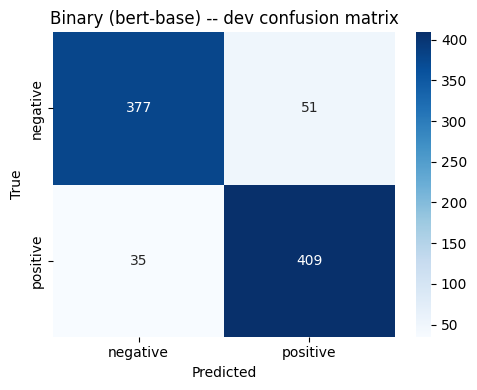

              precision    recall  f1-score   support

    negative       0.92      0.88      0.90       428
    positive       0.89      0.92      0.90       444

    accuracy                           0.90       872
   macro avg       0.90      0.90      0.90       872
weighted avg       0.90      0.90      0.90       872



In [ ]:
# confusion matrix + classification report

plot_confusion(labels_bin, preds_bin, ["negative", "positive"], "Binary (bert-base) -- dev confusion matrix")
print(classification_report(labels_bin, preds_bin, target_names=["negative", "positive"]))


In [ ]:
# errors sorted by confidence 

errors_bin = error_analysis_table(dev_bin, "label_binary", preds_bin, probs_bin,
                                   class_names={0: "negative", 1: "positive"})
display(errors_bin)


,sentence,true,pred,confidence
809,Although Huppert's intensity and focus has a r...,negative,positive,0.998565
275,Moretti's compelling anatomy of grief and the ...,negative,positive,0.998415
379,It's somewhat clumsy and too lethargically pac...,negative,positive,0.998396
178,This riveting World War II moral suspense stor...,negative,positive,0.996852
541,"The longer the movie goes, the worse it gets, ...",negative,positive,0.996740
741,American Chai encourages rueful laughter at st...,negative,positive,0.996392
469,"Very special effects, brilliantly bold colors ...",negative,positive,0.995898
37,"You won't like Roger, but you will quickly rec...",negative,positive,0.995735
451,"It's inoffensive, cheerful, built to inspire t...",negative,positive,0.995161
583,Manages to show life in all of its banality wh...,negative,positive,0.995123


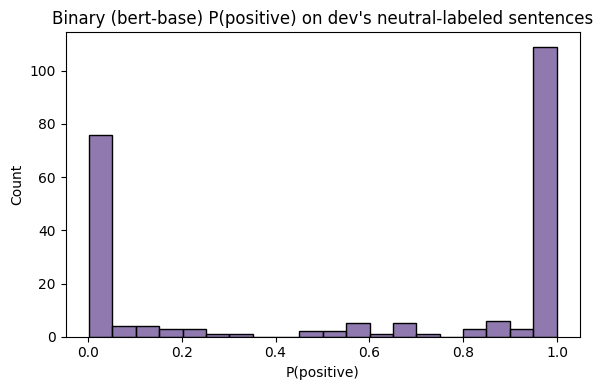

mean P(positive) on neutral sentences: 0.576  (0.5 = totally unsure)


In [ ]:
# see how model treats sentences it never saw a neutral label for

predict_proba_bin = make_predict_proba(model_bin, tokenizer)
neutral_dev = dev_df[dev_df["is_neutral"]]
neutral_probs_bin = predict_proba_bin(neutral_dev["sentence"].tolist())[:, 1]

plt.figure(figsize=(6, 4))
sns.histplot(neutral_probs_bin, bins=20, color="#6a4c93")
plt.title("Binary (bert-base) P(positive) on dev's neutral-labeled sentences")
plt.xlabel("P(positive)")
plt.tight_layout()
plt.show()
print(f"mean P(positive) on neutral sentences: {neutral_probs_bin.mean():.3f}  "
      f"(0.5 = totally unsure)")


**LIME.** perturbs the sentence (drops words around) and fits a little local linear model to see which words swing `predict_proba` the most.



>>> About a manga-like heroine who fights back at her abusers, it's energetic and satisfying if not deep and psychological.


,token,lime_weight
0,energetic,0.227853
1,satisfying,0.213004
2,and,0.186946
3,if,0.159881
4,psychological.,0.119780
5,it's,0.118735
6,"abusers,",0.108781
7,fights,0.083380
8,heroine,0.071377
9,deep,0.064865


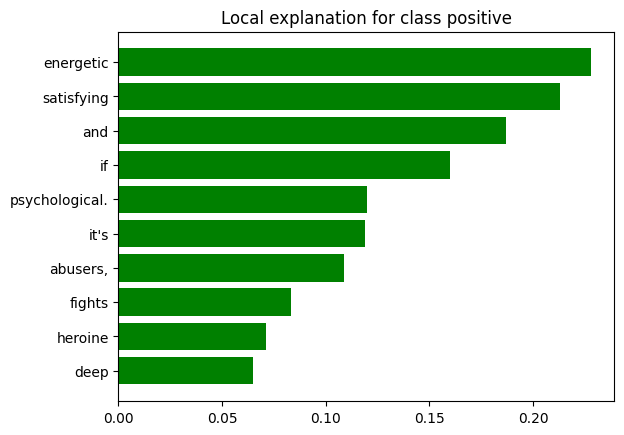


>>> Delivers the same old same old, tarted up with Latin flava and turned out by Hollywood playas.


,token,lime_weight
0,tarted,-0.130236
1,Delivers,0.085793
2,the,0.084523
3,Latin,0.062902
4,Hollywood,0.047888
5,with,0.036672
6,same,0.034698
7,turned,-0.032530
8,playas.,-0.031519
9,old,0.025861


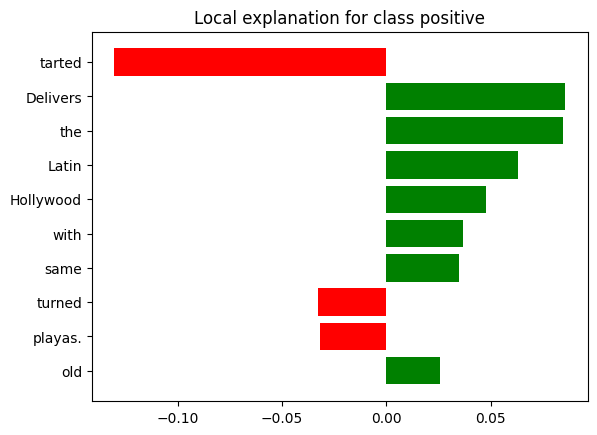


>>> Although Huppert's intensity and focus has a raw exhilaration about it, The Piano Teacher is anything but fun.


,token,lime_weight
0,fun.,0.189596
1,exhilaration,0.170965
2,intensity,0.081099
3,a,0.053843
4,Huppert's,0.044534
5,Piano,0.042840
6,Teacher,0.042300
7,focus,0.038149
8,and,0.033832
9,about,0.033300


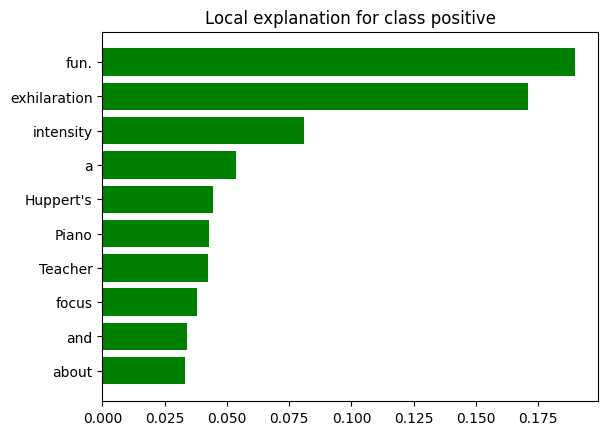

In [ ]:
from lime.lime_text import LimeTextExplainer

lime_explainer_bin = LimeTextExplainer(class_names=["negative", "positive"], bow=False, split_expression=r"\s+")

# get examples of confident-correct, and 1 borderline-correct, and one misclassified 
dev_bin_scored = dev_bin.copy()
dev_bin_scored["pred"] = preds_bin
dev_bin_scored["confidence"] = probs_bin.max(axis=1)
dev_bin_scored["correct"] = dev_bin_scored["pred"] == dev_bin_scored["label_binary"]

confident_correct = dev_bin_scored[dev_bin_scored["correct"]].sort_values("confidence", ascending=False).index[0]
borderline = dev_bin_scored[dev_bin_scored["correct"]].sort_values("confidence").index[0]
misclassified = (dev_bin_scored[~dev_bin_scored["correct"]].sort_values("confidence", ascending=False).index[0]
                 if (~dev_bin_scored["correct"]).any() else confident_correct)
chosen_bin_idx = [confident_correct, borderline, misclassified]

for idx in chosen_bin_idx:
    text = dev_bin.loc[idx, "sentence"]
    print("\n>>>", text)
    exp = lime_explainer_bin.explain_instance(text, predict_proba_bin, num_features=10, num_samples=800, labels=(1,))
    display(pd.DataFrame(exp.as_list(label=1), columns=["token", "lime_weight"]))
    exp.as_pyplot_figure(label=1)
    plt.show()


**SHAP.** measures each token's contribution by comparing against masked-out versions of the same sentence. Different lens from LIME for additional insight 


In [20]:
import shap

clf_pipeline_bin = pipeline(
    "text-classification", model=model_bin, tokenizer=tokenizer, top_k=None,
    device=0 if DEVICE.type == "cuda" else -1, truncation=True, max_length=MAX_LENGTH,
)
shap_explainer_bin = shap.Explainer(clf_pipeline_bin)
shap_values_bin = shap_explainer_bin([dev_bin.loc[idx, "sentence"] for idx in chosen_bin_idx])
for i in range(len(chosen_bin_idx)):
    shap.plots.text(shap_values_bin[i])

timer.stop()  # closes "binary_evaluation"


Device set to use cuda:0
You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  33%|███▎      | 1/3 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 100%|██████████| 3/3 [00:25<00:00,  4.85s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

... (2 outputs left out)

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

[binary_evaluation] done in 45.8s


45.7960657000076

### Observed

Overall this landed at 90.1% accuracy / 0.905 F1, pretty balanced between classes (negative: P0.92/R0.88, positive: P0.89/R0.92). But the top-15 highest-confidence mistakes (the error table above) are almost all the *same direction*: 14 out of 15 are true-negative sentences the model called positive at 99%+ confidence, and only 1 goes the other way. So even though the class-level metrics look balanced, when this model is wrong on a negative review it's usually very wrong and very sure about it. Worth digging into with LIME/SHAP below to see if there's a pattern (backhanded compliments, mixed reviews that lean negative but use a lot of positive-sounding words, that kind of thing). The neutral-sentence histogram above is the important bit for what's next: it shows how the model, having never seen a neutral label, spreads its confidence over genuinely ambiguous sentences -- using that directly in the bridge section below.


## 3.5 Bridge: = binary informs 5 class

- **Imbalance.** binary came out basically balanced (Sec 1), didn't need reweighting. 5-class is more imbalanced (extremes ~13-15% vs mid-classes ~26-27%, also Sec 1) -> so the 5-class model below gets a **class-weighted loss**.
- **Neutral is the new hard part.** that `P(positive)` histogram on neutral sentences up above shows the binary model is already pretty unsure about text it never trained on. For 5-class I'm tracking **macro-F1** instead of plain accuracy, so the neutral/mid-polarity confusion doesn't get drowned out by bigger classes.
- **Labels are ordinal.** 0-4 has an order to it, and most of the binary errors were near the boundary. Addded **adjacent accuracy** metric for 5class (`|pred - true| <= 1`) e.g. mixing up 3 and 4 is a small err vs 0 v 4.
- **Interpretability carryover.** whatever words showed up a lot in the binary LIME/SHAP output (negation, intensifiers, "but"-type conjunctions), I want to check if those same words show up again in the 5 class, just driving *degree* instead of polarity.
- **Hyperparameters mostly carry over** -- same model, tokenizer, MAX_LENGTH. bumping epics up for harder job + switch  `load_best_model_at_end` to target macro-F1 instead of binary F1.


In [ ]:
# free up GPU before next fine-tuning 
## keep numbers, drop model/optimizer state

binary_final_metrics = dict(eval_result_bin)  
del trainer_bin
import gc
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


## 4. Model Building = Fine-Grained 5 Class Classifier (bert-base)

Building straight off the bridge decisions above.. class-weighted loss, macro-F1 for picking the best checkpoint, same base hyperparams as binary


In [ ]:
# 5 class train/dev datasets (all labels, neutral stays in this time)

train_5c = train_df.copy()
dev_5c = dev_df.copy()

if SMOKE_TEST:
    train_5c = train_5c.sample(TRAIN_SUBSET, random_state=SEED).reset_index(drop=True)
    dev_5c = dev_5c.sample(min(DEV_SUBSET, len(dev_5c)), random_state=SEED).reset_index(drop=True)

train_ds_5c = SSTDataset(train_5c["sentence"], train_5c["label_5class"].astype(int), tokenizer)
dev_ds_5c = SSTDataset(dev_5c["sentence"], dev_5c["label_5class"].astype(int), tokenizer)
print(f"5-class train: {len(train_ds_5c)}  |  5-class dev: {len(dev_ds_5c)}")


5-class train: 8544  |  5-class dev: 1101


In [ ]:
# class weights (bridge finding 1) + a weighted-loss Trainer subclass

class_weights = compute_class_weight(
    class_weight="balanced", classes=np.arange(5), y=train_5c["label_5class"].to_numpy()
)
class_weights_t = torch.tensor(class_weights, dtype=torch.float)
print("class weights:", dict(zip(LABEL5_NAMES.values(), class_weights.round(2))))


class WeightedTrainer(Trainer):
    # only difference from normal trainer = cross-entropy loss gets the class weights baked in 
    # this gets reused later for the bert-large 5-class experiment too 
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss_fct = nn.CrossEntropyLoss(weight=self.class_weights.to(outputs.logits.device))
        loss = loss_fct(outputs.logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss


class weights: {'very negative': np.float64(1.56), 'negative': np.float64(0.77), 'neutral': np.float64(1.05), 'positive': np.float64(0.74), 'very positive': np.float64(1.33)}


In [ ]:
# model + TrainingArguments + WeightedTrainer for the 5class bert-base 

model_5c = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=5, id2label=LABEL5_NAMES, label2id={v: k for k, v in LABEL5_NAMES.items()},
).to(DEVICE)

args_5c = TrainingArguments(
    output_dir=str(OUTPUT_DIR / "5class_run"),
    num_train_epochs=EPOCHS_5CLASS,
    per_device_train_batch_size=BATCH_SIZE_TRAIN,
    per_device_eval_batch_size=BATCH_SIZE_EVAL,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_ratio=0.06,
    fp16=FP16,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=50,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    save_total_limit=2,
    seed=SEED,
    report_to="none",
)

trainer_5c = WeightedTrainer(
    model=model_5c,
    args=args_5c,
    train_dataset=train_ds_5c,
    eval_dataset=dev_ds_5c,
    data_collator=data_collator,
    compute_metrics=compute_metrics_factory(average="macro"),
    processing_class=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    class_weights=class_weights_t,
)

with timer.block("5class_training"):
    train_result_5c = trainer_5c.train()

send_sms_notification(f"5-class (bert-base) model built -- best dev macro-F1 so far: {trainer_5c.state.best_metric:.3f}")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.208700,1.129222,0.455949,0.476734,0.496092,0.456225
2,0.929900,1.151299,0.477748,0.479572,0.513400,0.481717
3,0.664500,1.349215,0.483197,0.484290,0.510746,0.488198
4,0.483100,1.566688,0.483197,0.481750,0.505376,0.486637
5,0.360600,1.700807,0.483197,0.482224,0.485278,0.481853


[5class_training] done in 262.9s
texted myself: '5-class (bert-base) model built -- best dev macro-F1 so far: 0.488'


### Decison Rationale 

class weighting fights ~2x imbalance noted in Sec 1. macro-F1 as the model selection metric (vs accuracy). Small extreme classes also matter for picking the best checkpoint. Other (e.g LR, batch size, `fp16`, `MAX_LENGTH`) is same as binary (same Sec 1 length analysis


## 5. Model Evaluation and Interpretation for 5-Class (bert-base)


In [25]:
timer.start("5class_evaluation")

eval_result_5c = trainer_5c.evaluate()
display(pd.Series(eval_result_5c))

pred_output_5c = trainer_5c.predict(dev_ds_5c)
probs_5c = torch.softmax(torch.tensor(pred_output_5c.predictions), dim=-1).numpy()
preds_5c = np.argmax(probs_5c, axis=-1)
labels_5c = pred_output_5c.label_ids

adjacent_acc = float(np.mean(np.abs(preds_5c - labels_5c) <= 1))
print(f"adjacent accuracy (|pred - true| <= 1): {adjacent_acc:.3f}")


eval_loss                    1.349215
eval_accuracy                0.483197
eval_precision               0.484290
eval_recall                  0.510746
eval_f1                      0.488198
eval_runtime                 1.137100
eval_samples_per_second    968.244000
eval_steps_per_second       30.780000
epoch                        5.000000
dtype: float64

adjacent accuracy (|pred - true| <= 1): 0.913


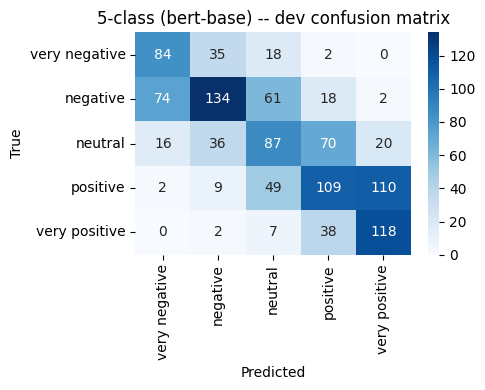

               precision    recall  f1-score   support

very negative       0.48      0.60      0.53       139
     negative       0.62      0.46      0.53       289
      neutral       0.39      0.38      0.39       229
     positive       0.46      0.39      0.42       279
very positive       0.47      0.72      0.57       165

     accuracy                           0.48      1101
    macro avg       0.48      0.51      0.49      1101
 weighted avg       0.49      0.48      0.48      1101



In [ ]:
# confusion matrix 
## expecting most of the errors to be adjacent-class stuff vs way off

class_names_5c = [LABEL5_NAMES[i] for i in range(5)]
plot_confusion(labels_5c, preds_5c, class_names_5c, "5-class (bert-base) -- dev confusion matrix")
print(classification_report(labels_5c, preds_5c, target_names=class_names_5c))


In [ ]:
# Deeper look = show results w/ error breakdown by by "off by one class" vs "flipped polarity" 

dev_5c_scored = dev_5c.copy()
dev_5c_scored["pred"] = preds_5c
dev_5c_scored["confidence"] = probs_5c.max(axis=1)
dev_5c_scored["abs_diff"] = (dev_5c_scored["pred"] - dev_5c_scored["label_5class"]).abs()
dev_5c_scored["error_type"] = np.select(
    [dev_5c_scored["pred"] == dev_5c_scored["label_5class"], dev_5c_scored["abs_diff"] <= 1],
    ["correct", "adjacent-class error"],
    default="polarity-flip error",
)
print(dev_5c_scored["error_type"].value_counts())

errors_5c = error_analysis_table(dev_5c, "label_5class", preds_5c, probs_5c, class_names=LABEL5_NAMES)
display(errors_5c)


error_type
correct                 532
adjacent-class error    473
polarity-flip error      96
Name: count, dtype: int64


,sentence,true,pred,confidence
226,"An operatic, sprawling picture that's entertai...",positive,very positive,0.977019
513,"Oscar Wilde's masterpiece, The Importance of B...",positive,very positive,0.973604
293,A superbly acted and funny/gritty fable of the...,positive,very positive,0.971923
425,"... Brian De Palma is utterly mad: cinema mad,...",neutral,very negative,0.970362
123,LaPaglia's ability to convey grief and hope wo...,positive,very positive,0.969517
432,"A gorgeous, witty, seductive movie.",positive,very positive,0.968873
1072,This is a train wreck of an action film--a stu...,negative,very negative,0.968482
33,It's a stunning lyrical work of considerable f...,positive,very positive,0.968237
739,"To call The Other Side of Heaven ""appalling"" w...",negative,very negative,0.967909
766,A coarse and stupid gross-out.,negative,very negative,0.967175


**LIME on 5 class**


>>> An exquisitely crafted and acted tale.


,token,lime_weight
0,exquisitely,0.667370
1,crafted,0.234368
2,tale.,0.234168
3,and,0.140637
4,acted,0.136707
5,An,0.134588


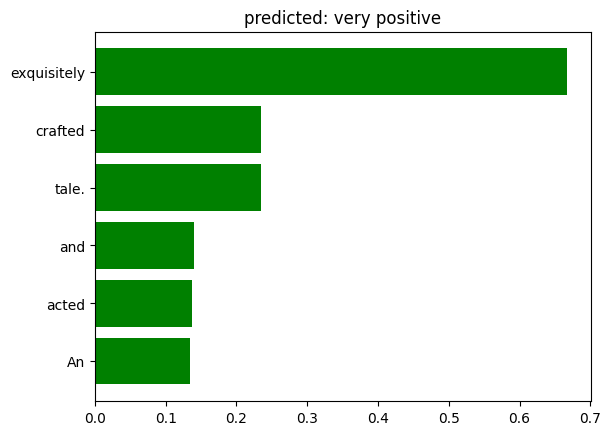


>>> An operatic, sprawling picture that's entertainingly acted, magnificently shot and gripping enough to sustain most of its 170-minute length.


,token,lime_weight
0,magnificently,0.454269
1,"acted,",0.174623
2,entertainingly,0.159543
3,to,0.084374
4,"operatic,",0.077171
5,and,0.074019
6,of,0.073124
7,picture,0.071072
8,shot,0.066112
9,gripping,0.060127


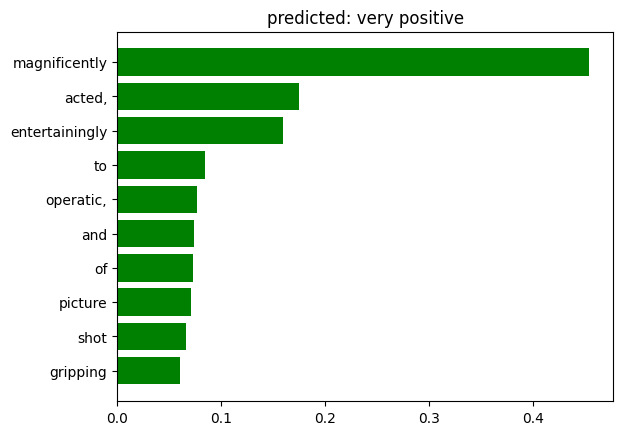


>>> ... Brian De Palma is utterly mad: cinema mad, set-piece mad, style mad.


,token,lime_weight
0,mad.,0.186913
1,mad:,0.135659
2,"mad,",0.124084
3,"mad,",0.104583
4,...,0.059893
5,utterly,0.055397
6,set-piece,0.045813
7,cinema,0.035559
8,is,0.028225
9,De,0.021009


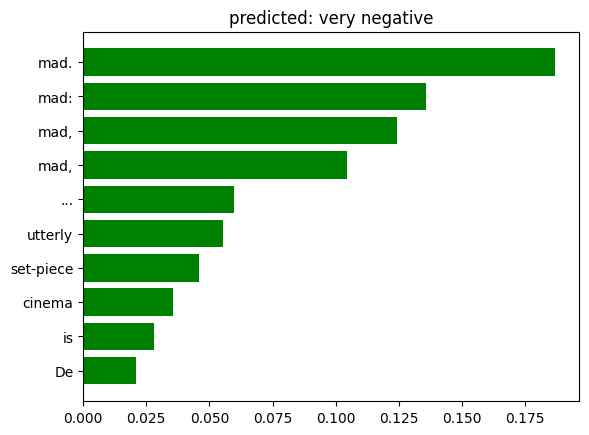

In [28]:
lime_explainer_5c = LimeTextExplainer(class_names=class_names_5c, bow=False, split_expression=r"\s+")

dev_5c_scored["correct"] = dev_5c_scored["pred"] == dev_5c_scored["label_5class"]
confident_correct_5c = dev_5c_scored[dev_5c_scored["correct"]].sort_values("confidence", ascending=False).index[0]
adjacent_error_5c = (dev_5c_scored[dev_5c_scored["error_type"] == "adjacent-class error"].sort_values(
    "confidence", ascending=False).index[0]
    if (dev_5c_scored["error_type"] == "adjacent-class error").any() else confident_correct_5c)
polarity_flip_5c = (dev_5c_scored[dev_5c_scored["error_type"] == "polarity-flip error"].sort_values(
    "confidence", ascending=False).index[0]
    if (dev_5c_scored["error_type"] == "polarity-flip error").any() else adjacent_error_5c)
chosen_5c_idx = [confident_correct_5c, adjacent_error_5c, polarity_flip_5c]

predict_proba_5c = make_predict_proba(model_5c, tokenizer)
for idx in chosen_5c_idx:
    text = dev_5c.loc[idx, "sentence"]
    print("\n>>>", text)
    exp = lime_explainer_5c.explain_instance(text, predict_proba_5c, num_features=10, num_samples=800, top_labels=1)
    top_label = exp.available_labels()[0]
    display(pd.DataFrame(exp.as_list(label=top_label), columns=["token", "lime_weight"]))
    exp.as_pyplot_figure(label=top_label)
    plt.title(f"predicted: {class_names_5c[top_label]}")
    plt.show()


**SHAP 5 class**

In [29]:
clf_pipeline_5c = pipeline(
    "text-classification", model=model_5c, tokenizer=tokenizer, top_k=None,
    device=0 if DEVICE.type == "cuda" else -1, truncation=True, max_length=MAX_LENGTH,
)
shap_explainer_5c = shap.Explainer(clf_pipeline_5c)
shap_values_5c = shap_explainer_5c([dev_5c.loc[idx, "sentence"] for idx in chosen_5c_idx])
for i in range(len(chosen_5c_idx)):
    shap.plots.text(shap_values_5c[i])

timer.stop()  # closes "5class_evaluation"


Device set to use cuda:0


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  67%|██████▋   | 2/3 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 4it [00:23, 11.81s/it]               


<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

[5class_evaluation] done in 29.6s


29.64486569998553

### Observations

Sec 3.5's prediction held up: 473 of the 569 total errors are adjacent-class (off by one notch) vs. only 96 true polarity flips. Adjacent accuracy came out to 91.3% even though exact accuracy is only 48.3%. So the model is usually close when not exactly. Interesting that from the error table... highest-confidence mistakes (99%+) are all the model pushing to an *extreme* label when the true label is one notch milder like calling it "very positive" when it's really "positive,". Overrconfidence that after it decides pos or neg, tends to overshoot toward the extreme


In [30]:
# pulling together the binary + 5-class bert-base numbers already computed above
bert_base_summary = pd.DataFrame({
    "binary (bert-base)": {"accuracy": binary_final_metrics.get("eval_accuracy"), "f1": binary_final_metrics.get("eval_f1")},
    "5-class (bert-base)": {"accuracy": eval_result_5c.get("eval_accuracy"), "f1": eval_result_5c.get("eval_f1"),
                             "adjacent_accuracy": adjacent_acc},
})
display(bert_base_summary)


,binary (bert-base),5-class (bert-base)
accuracy,0.901376,0.483197
f1,0.904867,0.488198
adjacent_accuracy,NaN,0.912807


BERT-LARGE ATTEMPT 

- bert-large has roughly 3x the parameters of base
- Sec 1 already flagged 5 class imbalance. More capacity + learning-rate search might help the minority classes specifically, instead of me just picking LR 
- runtime has not been an issue 

Plan is to use same 2 stage as before (binary then 5class) just replacing w/ bert-large-cased-whole-word-masking + grid search for LR

6GB VRAM constraint... AdamW optimizer default eats too much memory regardless of batch size I picked. Switched to adafactor optimizer instead, plus gradient checkpointing 


In [ ]:
# new stuff for the bert-large experiment

MODEL_NAME_LARGE = "bert-large-cased-whole-word-masking"
LR_GRID = [1e-5, 2e-5, 3e-5]  # lower range than bert-base -- bigger models get twitchy at higher LRs

if SMOKE_TEST:
    EPOCHS_BINARY_LARGE, EPOCHS_5CLASS_LARGE = 1, 1
else:
    EPOCHS_BINARY_LARGE, EPOCHS_5CLASS_LARGE = 6, 8  # bumped up since lower LRs converge slower


## 6. Model Building == Binary Classifier w/ bert-large + LR search


In [ ]:
# LR search for the binary bert-large model -- full training run per LR 
# each saved to its own folder, best picked after loop 

import gc

search_results_bin_large = []

for lr in LR_GRID:
    run_dir = OUTPUT_DIR / "binary_large_run" / f"lr_{lr:.0e}"
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME_LARGE, num_labels=2, id2label={0: "negative", 1: "positive"}, label2id={"negative": 0, "positive": 1},
    ).to(DEVICE)

    args = TrainingArguments(
        output_dir=str(run_dir),
        learning_rate=lr,
        num_train_epochs=EPOCHS_BINARY_LARGE,
        per_device_train_batch_size=BATCH_SIZE_TRAIN,
        per_device_eval_batch_size=BATCH_SIZE_EVAL,
        optim="adafactor",  # AdamW's optimizer state doesn't fit bert-large in 6GB VRAM
        gradient_checkpointing=True,  # extra memory headroom 
        weight_decay=0.01,
        warmup_ratio=0.06,
        fp16=FP16,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=SEED,
        report_to="none",
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds_bin,
        eval_dataset=dev_ds_bin,
        data_collator=data_collator,
        compute_metrics=compute_metrics_factory(average="binary"),
        processing_class=tokenizer,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
    )

    with timer.block(f"binary_large_training_lr_{lr:.0e}"):
        trainer.train()

    search_results_bin_large.append({
        "lr": lr, "best_f1": trainer.state.best_metric, "best_checkpoint": trainer.state.best_model_checkpoint,
    })
    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

search_df_bin_large = pd.DataFrame(search_results_bin_large).sort_values("best_f1", ascending=False)
display(search_df_bin_large)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.234700,0.204409,0.920872,0.923251,0.921171,0.922210
2,0.196300,0.289442,0.931193,0.906780,0.963964,0.934498
3,0.061800,0.377372,0.934633,0.929047,0.943694,0.936313
4,0.031100,0.451210,0.934633,0.930958,0.941441,0.936170
5,0.025400,0.513292,0.932339,0.930649,0.936937,0.933782
6,0.000100,0.508668,0.934633,0.936795,0.934685,0.935738


[binary_large_training_lr_1e-05] done in 1238.2s


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.272900,0.194392,0.928899,0.928251,0.932432,0.930337
2,0.184400,0.349006,0.915138,0.893617,0.945946,0.919037
3,0.093700,0.497800,0.927752,0.924276,0.934685,0.929451
4,0.019500,0.566880,0.924312,0.909091,0.945946,0.927152


[binary_large_training_lr_2e-05] done in 781.6s


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.297900,0.198803,0.922018,0.915929,0.932432,0.924107
2,0.158300,0.287050,0.919725,0.951691,0.887387,0.918415
3,0.116100,0.514343,0.917431,0.938679,0.896396,0.917051
4,0.035700,0.605289,0.916284,0.922551,0.912162,0.917327


[binary_large_training_lr_3e-05] done in 870.6s


,lr,best_f1,best_checkpoint
0,0.00001,0.936313,outputs\a...
1,0.00002,0.930337,outputs\a...
2,0.00003,0.924107,outputs\a...


In [ ]:
# Best LR and reload checkpoint 

best_row_bin_large = search_df_bin_large.iloc[0]
model_bin_large = AutoModelForSequenceClassification.from_pretrained(best_row_bin_large["best_checkpoint"]).to(DEVICE)

send_sms_notification(
    f"Binary (bert-large) tuned -- best LR={best_row_bin_large['lr']:.0e}, dev F1={best_row_bin_large['best_f1']:.3f}"
)


texted myself: 'Binary (bert-large) tuned -- best LR=1e-05, dev F1=0.936'


### quick note on these settings

Went with `adafactor` instead of default AdamW because AdamW's two fp32 momentum buffers alone push past 6GB regardless of batch size or gradient checkpointing). Gradient checkpointing for extra insurance since this loop runs several training cycles back to back in one process.

LR grid is lower than what I used for bert-base (1e-5 to 3e-5 vs. a fixed 2e-5) since expecting big model will be less stable at higher LR on small data


## 7. Model Evaluation and Interpretation for Binary (bert-large)


In [ ]:
timer.start("binary_large_evaluation")

# eval-only wrapper around the reloaded checkpoint -- never calls .train() 
### no optimizer ever gets created for it (low VRAM hit

trainer_bin_large = Trainer(
    model=model_bin_large,
    args=TrainingArguments(output_dir=str(OUTPUT_DIR / "binary_large_run" / "eval_only"), report_to="none",
                            per_device_eval_batch_size=BATCH_SIZE_EVAL),
    eval_dataset=dev_ds_bin,
    data_collator=data_collator,
    compute_metrics=compute_metrics_factory(average="binary"),
    processing_class=tokenizer,
)

eval_result_bin_large = trainer_bin_large.evaluate()
display(pd.Series(eval_result_bin_large))

pred_output_bin_large = trainer_bin_large.predict(dev_ds_bin)
probs_bin_large = torch.softmax(torch.tensor(pred_output_bin_large.predictions), dim=-1).numpy()
preds_bin_large = np.argmax(probs_bin_large, axis=-1)
labels_bin_large = pred_output_bin_large.label_ids


eval_loss                        0.377372
eval_model_preparation_time      0.005000
eval_accuracy                    0.934633
eval_precision                   0.929047
eval_recall                      0.943694
eval_f1                          0.936313
eval_runtime                     2.343700
eval_samples_per_second        372.065000
eval_steps_per_second           11.947000
dtype: float64

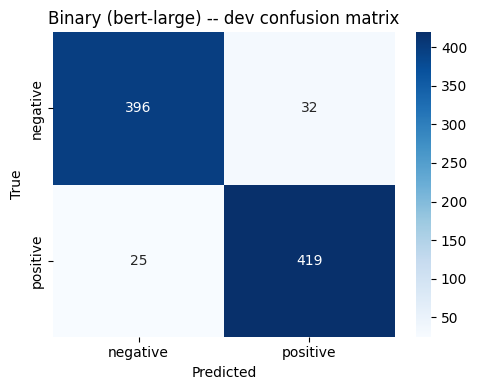

              precision    recall  f1-score   support

    negative       0.94      0.93      0.93       428
    positive       0.93      0.94      0.94       444

    accuracy                           0.93       872
   macro avg       0.93      0.93      0.93       872
weighted avg       0.93      0.93      0.93       872



In [35]:
plot_confusion(labels_bin_large, preds_bin_large, ["negative", "positive"], "Binary (bert-large) -- dev confusion matrix")
print(classification_report(labels_bin_large, preds_bin_large, target_names=["negative", "positive"]))


In [36]:
errors_bin_large = error_analysis_table(dev_bin, "label_binary", preds_bin_large, probs_bin_large,
                                         class_names={0: "negative", 1: "positive"})
display(errors_bin_large)


,sentence,true,pred,confidence
275,Moretti's compelling anatomy of grief and the ...,negative,positive,0.999839
379,It's somewhat clumsy and too lethargically pac...,negative,positive,0.999834
178,This riveting World War II moral suspense stor...,negative,positive,0.999822
826,Verbinski implements every hack-artist trick t...,negative,positive,0.999761
37,"You won't like Roger, but you will quickly rec...",negative,positive,0.999753
486,Rarely has leukemia looked so shimmering and b...,negative,positive,0.999740
485,"The lower your expectations, the more you'll e...",negative,positive,0.999740
109,Reign of Fire looks as if it was made without ...,positive,negative,0.999731
646,a by-the-numbers patient/doctor pic that cover...,negative,positive,0.999663
247,As unseemly as its title suggests.,positive,negative,0.999659


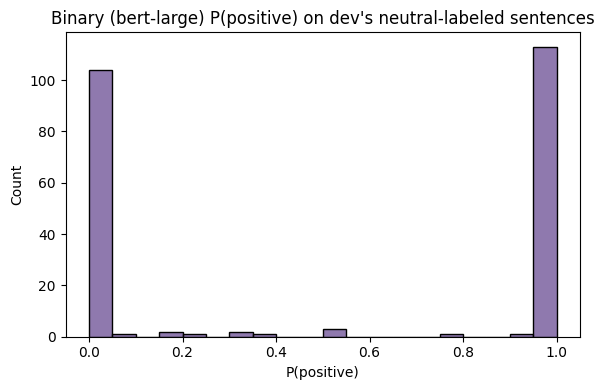

mean P(positive) on neutral sentences: 0.515


In [ ]:
# same neutral sentence check as Sec 3 pointed at big model

predict_proba_bin_large = make_predict_proba(model_bin_large, tokenizer)
neutral_probs_bin_large = predict_proba_bin_large(neutral_dev["sentence"].tolist())[:, 1]

plt.figure(figsize=(6, 4))
sns.histplot(neutral_probs_bin_large, bins=20, color="#6a4c93")
plt.title("Binary (bert-large) P(positive) on dev's neutral-labeled sentences")
plt.xlabel("P(positive)")
plt.tight_layout()
plt.show()
print(f"mean P(positive) on neutral sentences: {neutral_probs_bin_large.mean():.3f}")


LIME for bert-large


>>> A strangely compelling and brilliantly acted psychological drama.


,token,lime_weight
0,brilliantly,0.233397
1,drama.,0.176039
2,compelling,0.113017
3,strangely,0.099281
4,psychological,0.054733
5,acted,0.035748
6,and,0.028146
7,A,-0.003720


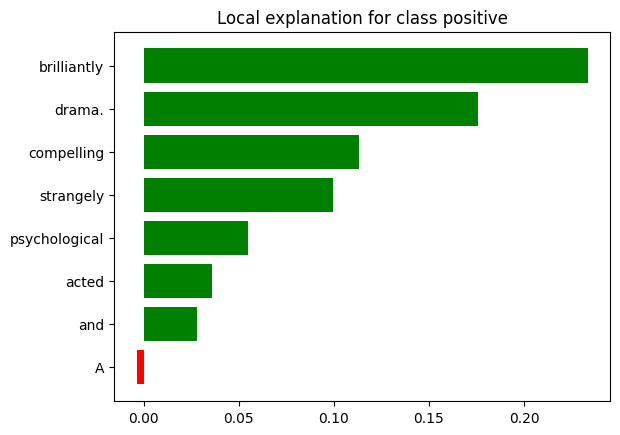


>>> We root for (Clara and Paul), even like them, though perhaps it's an emotion closer to pity.


,token,lime_weight
0,pity.,-0.346537
1,We,0.155163
2,(Clara,0.115728
3,emotion,0.103158
4,"Paul),",0.088030
5,like,-0.085815
6,even,-0.083141
7,for,0.082706
8,and,0.081632
9,root,0.074255


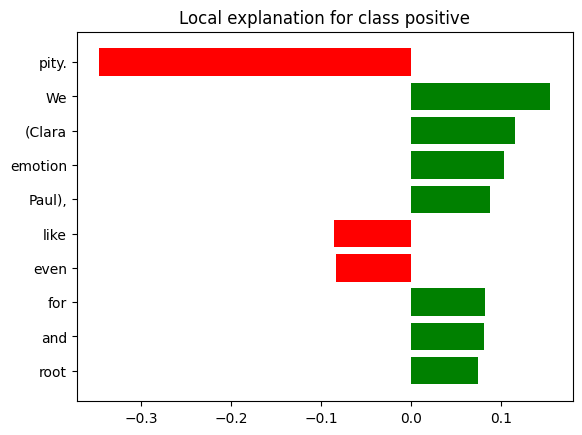


>>> Moretti's compelling anatomy of grief and the difficult process of adapting to loss.


,token,lime_weight
0,Moretti's,0.286711
1,compelling,0.215926
2,anatomy,0.186905
3,the,0.184107
4,of,0.180073
5,grief,0.161829
6,adapting,0.159126
7,process,0.140876
8,and,0.114493
9,of,0.092207


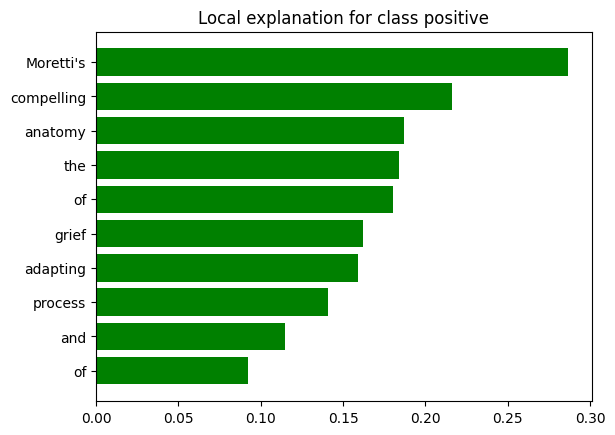

In [38]:
lime_explainer_bin_large = LimeTextExplainer(class_names=["negative", "positive"], bow=False, split_expression=r"\s+")

dev_bin_scored_large = dev_bin.copy()
dev_bin_scored_large["pred"] = preds_bin_large
dev_bin_scored_large["confidence"] = probs_bin_large.max(axis=1)
dev_bin_scored_large["correct"] = dev_bin_scored_large["pred"] == dev_bin_scored_large["label_binary"]

confident_correct_l = dev_bin_scored_large[dev_bin_scored_large["correct"]].sort_values("confidence", ascending=False).index[0]
borderline_l = dev_bin_scored_large[dev_bin_scored_large["correct"]].sort_values("confidence").index[0]
misclassified_l = (dev_bin_scored_large[~dev_bin_scored_large["correct"]].sort_values("confidence", ascending=False).index[0]
                    if (~dev_bin_scored_large["correct"]).any() else confident_correct_l)
chosen_bin_large_idx = [confident_correct_l, borderline_l, misclassified_l]

for idx in chosen_bin_large_idx:
    text = dev_bin.loc[idx, "sentence"]
    print("\n>>>", text)
    exp = lime_explainer_bin_large.explain_instance(text, predict_proba_bin_large, num_features=10, num_samples=800, labels=(1,))
    display(pd.DataFrame(exp.as_list(label=1), columns=["token", "lime_weight"]))
    exp.as_pyplot_figure(label=1)
    plt.show()


SHAP

In [39]:
clf_pipeline_bin_large = pipeline(
    "text-classification", model=model_bin_large, tokenizer=tokenizer, top_k=None,
    device=0 if DEVICE.type == "cuda" else -1, truncation=True, max_length=MAX_LENGTH,
)
shap_explainer_bin_large = shap.Explainer(clf_pipeline_bin_large)
shap_values_bin_large = shap_explainer_bin_large([dev_bin.loc[idx, "sentence"] for idx in chosen_bin_large_idx])
for i in range(len(chosen_bin_large_idx)):
    shap.plots.text(shap_values_bin_large[i])

timer.stop()  # closes "binary_large_evaluation"


Device set to use cuda:0


  0%|          | 0/132 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  67%|██████▋   | 2/3 [00:00<?, ?it/s]

  0%|          | 0/380 [00:00<?, ?it/s]

PartitionExplainer explainer: 4it [00:45, 23.00s/it]               


<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

[binary_large_evaluation] done in 60.8s


60.78396520001115

### Observations

Bigger model + LR search improved == 93.5% accuracy / 0.936 F1 vs. bert-base's 90.1% / 0.905 (Sec 3) = 3.3 point accuracy improvement. Best LR out of the grid was 1e-05. 

## 8. Model Building == 5-Class Classifier w/ bert-large + LR search


In [ ]:
# LR search for 5 class bert-large model

search_results_5c_large = []

for lr in LR_GRID:
    run_dir = OUTPUT_DIR / "5class_large_run" / f"lr_{lr:.0e}"
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME_LARGE, num_labels=5, id2label=LABEL5_NAMES, label2id={v: k for k, v in LABEL5_NAMES.items()},
    ).to(DEVICE)

    args = TrainingArguments(
        output_dir=str(run_dir),
        learning_rate=lr,
        num_train_epochs=EPOCHS_5CLASS_LARGE,
        per_device_train_batch_size=BATCH_SIZE_TRAIN,
        per_device_eval_batch_size=BATCH_SIZE_EVAL,
        optim="adafactor",
        gradient_checkpointing=True,
        weight_decay=0.01,
        warmup_ratio=0.06,
        fp16=FP16,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=50,
        load_best_model_at_end=True,
        metric_for_best_model="f1",
        greater_is_better=True,
        save_total_limit=1,
        seed=SEED,
        report_to="none",
    )

    trainer = WeightedTrainer(
        model=model,
        args=args,
        train_dataset=train_ds_5c,
        eval_dataset=dev_ds_5c,
        data_collator=data_collator,
        compute_metrics=compute_metrics_factory(average="macro"),
        processing_class=tokenizer,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
        class_weights=class_weights_t,
    )

    with timer.block(f"5class_large_training_lr_{lr:.0e}"):
        trainer.train()

    search_results_5c_large.append({
        "lr": lr, "best_f1": trainer.state.best_metric, "best_checkpoint": trainer.state.best_model_checkpoint,
    })
    del trainer, model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

search_df_5c_large = pd.DataFrame(search_results_5c_large).sort_values("best_f1", ascending=False)
display(search_df_5c_large)


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.177200,1.083812,0.473206,0.497731,0.520415,0.469469
2,0.946100,1.169096,0.449591,0.478207,0.511942,0.448592
3,0.783000,1.233895,0.506812,0.504916,0.537592,0.507043
4,0.484600,1.414172,0.514986,0.510711,0.547953,0.516231
5,0.368700,1.613548,0.532243,0.525868,0.544114,0.531665
6,0.239200,1.977160,0.526794,0.523700,0.512637,0.516824
7,0.208800,2.208310,0.526794,0.520993,0.527918,0.523433
8,0.146900,2.346058,0.530427,0.522905,0.532599,0.526442


[5class_large_training_lr_1e-05] done in 26519.9s


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.169500,1.159748,0.456857,0.517604,0.484826,0.440723
2,0.938000,1.214108,0.425068,0.454759,0.500597,0.413574
3,0.681100,1.276554,0.514078,0.511741,0.544375,0.512281
4,0.395100,1.568424,0.534968,0.525145,0.537944,0.528366
5,0.232800,2.088367,0.533152,0.525658,0.524140,0.523272
6,0.120400,2.619691,0.533152,0.524774,0.527185,0.523452
7,0.088700,3.188875,0.530427,0.523414,0.523281,0.522266


[5class_large_training_lr_2e-05] done in 1859.9s


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-large-cased-whole-word-masking and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,1.174000,1.221490,0.423252,0.506749,0.426416,0.398639
2,0.965500,1.157162,0.444142,0.465453,0.510063,0.440341
3,0.670400,1.310157,0.498638,0.494569,0.528339,0.493879
4,0.361700,1.584623,0.504995,0.499065,0.530039,0.502950
5,0.224400,2.325878,0.520436,0.523697,0.491984,0.498759
6,0.102800,3.030535,0.529519,0.525327,0.506604,0.508308
7,0.101000,3.654782,0.517711,0.516669,0.495678,0.500376
8,0.062200,3.900018,0.513170,0.510042,0.495645,0.499726


[5class_large_training_lr_3e-05] done in 2154.1s


,lr,best_f1,best_checkpoint
0,0.00001,0.531665,outputs\a...
1,0.00002,0.528366,outputs\a...
2,0.00003,0.508308,outputs\a...


In [41]:
best_row_5c_large = search_df_5c_large.iloc[0]
model_5c_large = AutoModelForSequenceClassification.from_pretrained(best_row_5c_large["best_checkpoint"]).to(DEVICE)

send_sms_notification(
    f"5-class (bert-large) tuned -- best LR={best_row_5c_large['lr']:.0e}, dev macro-F1={best_row_5c_large['best_f1']:.3f}"
)


texted myself: '5-class (bert-large) tuned -- best LR=1e-05, dev macro-F1=0.532'


# LONG RUN OVERNIGHT

lr=1e-05 run took **26,520 seconds (~7.4 hours)** to finish, vs. 1,860s and 2,154s for lr=2e-05 and lr=3e-05. 
lr=1e-05 on top but only by 0.004 macro-F1 over lr=2e-05
If compute/timing was important, would def choose lr=2e-05 


## 9. Model Eval + Interp == 5 Class w bert large


In [ ]:
timer.start("5class_large_evaluation")

# eval-only WeightedTrainer wrapper 
## keeping WeightedTrainer so reported eval_loss stays consistent with what was optimized during search
trainer_5c_large = WeightedTrainer(
    model=model_5c_large,
    args=TrainingArguments(output_dir=str(OUTPUT_DIR / "5class_large_run" / "eval_only"), report_to="none",
                            per_device_eval_batch_size=BATCH_SIZE_EVAL),
    eval_dataset=dev_ds_5c,
    data_collator=data_collator,
    compute_metrics=compute_metrics_factory(average="macro"),
    processing_class=tokenizer,
    class_weights=class_weights_t,
)

eval_result_5c_large = trainer_5c_large.evaluate()
display(pd.Series(eval_result_5c_large))

pred_output_5c_large = trainer_5c_large.predict(dev_ds_5c)
probs_5c_large = torch.softmax(torch.tensor(pred_output_5c_large.predictions), dim=-1).numpy()
preds_5c_large = np.argmax(probs_5c_large, axis=-1)
labels_5c_large = pred_output_5c_large.label_ids

adjacent_acc_large = float(np.mean(np.abs(preds_5c_large - labels_5c_large) <= 1))
print(f"adjacent accuracy (bert-large): {adjacent_acc_large:.3f}")


eval_loss                        1.613548
eval_model_preparation_time      0.005000
eval_accuracy                    0.532243
eval_precision                   0.525868
eval_recall                      0.544114
eval_f1                          0.531665
eval_runtime                     2.964500
eval_samples_per_second        371.396000
eval_steps_per_second           11.806000
dtype: float64

adjacent accuracy (bert-large): 0.943


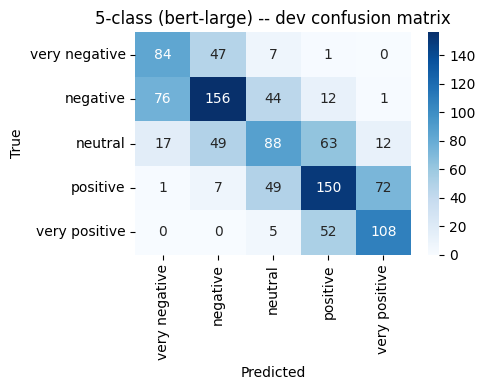

               precision    recall  f1-score   support

very negative       0.47      0.60      0.53       139
     negative       0.60      0.54      0.57       289
      neutral       0.46      0.38      0.42       229
     positive       0.54      0.54      0.54       279
very positive       0.56      0.65      0.60       165

     accuracy                           0.53      1101
    macro avg       0.53      0.54      0.53      1101
 weighted avg       0.53      0.53      0.53      1101



In [43]:
plot_confusion(labels_5c_large, preds_5c_large, class_names_5c, "5-class (bert-large) -- dev confusion matrix")
print(classification_report(labels_5c_large, preds_5c_large, target_names=class_names_5c))


In [44]:
dev_5c_scored_large = dev_5c.copy()
dev_5c_scored_large["pred"] = preds_5c_large
dev_5c_scored_large["confidence"] = probs_5c_large.max(axis=1)
dev_5c_scored_large["abs_diff"] = (dev_5c_scored_large["pred"] - dev_5c_scored_large["label_5class"]).abs()
dev_5c_scored_large["error_type"] = np.select(
    [dev_5c_scored_large["pred"] == dev_5c_scored_large["label_5class"], dev_5c_scored_large["abs_diff"] <= 1],
    ["correct", "adjacent-class error"],
    default="polarity-flip error",
)
print(dev_5c_scored_large["error_type"].value_counts())

errors_5c_large = error_analysis_table(dev_5c, "label_5class", preds_5c_large, probs_5c_large, class_names=LABEL5_NAMES)
display(errors_5c_large)


error_type
correct                 586
adjacent-class error    452
polarity-flip error      63
Name: count, dtype: int64


,sentence,true,pred,confidence
33,It's a stunning lyrical work of considerable f...,positive,very positive,0.994590
1057,A sequence of ridiculous shoot - 'em - up scenes.,negative,very negative,0.994092
984,"It's another stale, kill-by-numbers flick, com...",negative,very negative,0.993991
387,"Just as moving, uplifting and funny as ever.",positive,very positive,0.993808
684,Has a long and clunky ending...which forces th...,neutral,very negative,0.993724
1013,"Complete lack of originality, cleverness or ev...",negative,very negative,0.993635
226,"An operatic, sprawling picture that's entertai...",positive,very positive,0.993399
1077,At least one scene is so disgusting that viewe...,negative,very negative,0.993393
432,"A gorgeous, witty, seductive movie.",positive,very positive,0.993356
752,... nothing scary here except for some awful a...,negative,very negative,0.993351


LIME for bigger 5-class model


>>> One of the best films of the year with its exploration of the obstacles to happiness faced by five contemporary individuals...a psychological masterpiece.


,token,lime_weight
0,masterpiece.,0.365281
1,best,0.222392
2,individuals...a,0.208872
3,exploration,0.150190
4,the,0.142417
5,One,0.132680
6,contemporary,0.123441
7,films,0.113418
8,of,0.110151
9,of,0.094400


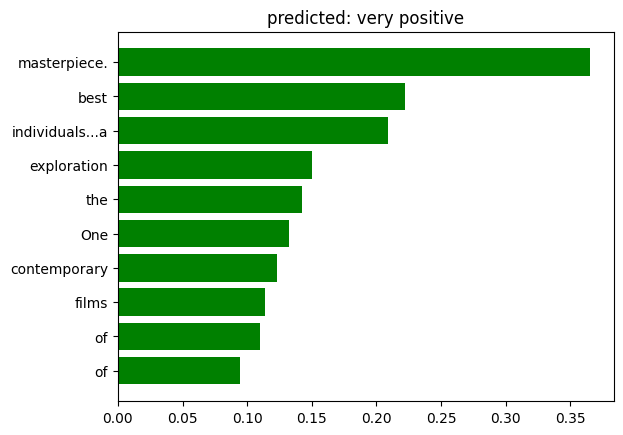


>>> It's a stunning lyrical work of considerable force and truth.


,token,lime_weight
0,stunning,0.414435
1,and,0.215292
2,work,0.207319
3,lyrical,0.199052
4,of,0.141830
5,a,0.138427
6,It's,0.128803
7,force,0.109439
8,truth.,0.050555
9,considerable,0.009208


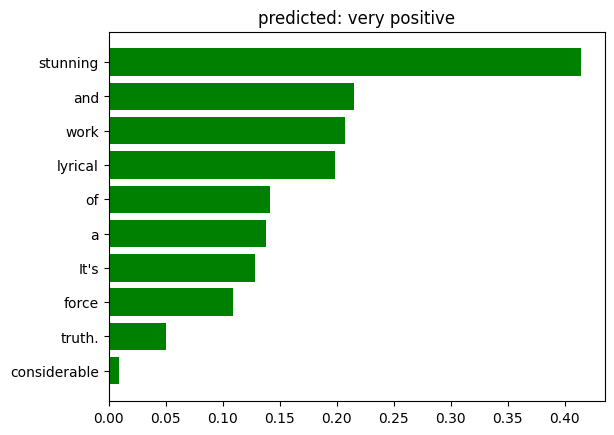


>>> Has a long and clunky ending...which forces the audience to fidget through ten pseudo-serious minutes while waiting for the ending credits and the deleted scenes montage to break the audience's awkward silence


,token,lime_weight
0,clunky,0.317845
1,ending...which,0.221146
2,forces,0.156381
3,minutes,0.139972
4,to,0.124756
5,for,0.123937
6,through,0.120262
7,the,0.111600
8,break,0.095330
9,credits,0.088573


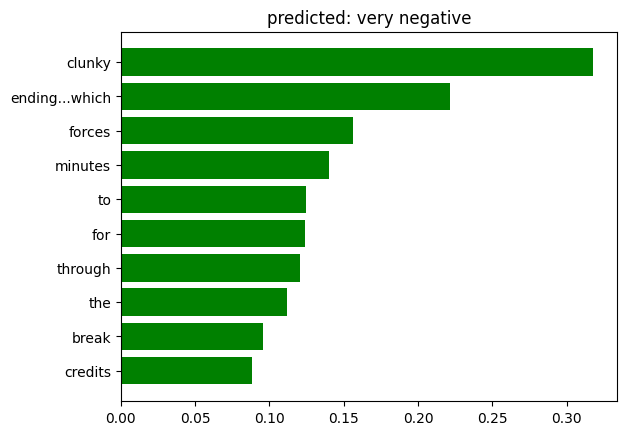

In [45]:
lime_explainer_5c_large = LimeTextExplainer(class_names=class_names_5c, bow=False, split_expression=r"\s+")

dev_5c_scored_large["correct"] = dev_5c_scored_large["pred"] == dev_5c_scored_large["label_5class"]
confident_correct_5c_l = dev_5c_scored_large[dev_5c_scored_large["correct"]].sort_values("confidence", ascending=False).index[0]
adjacent_error_5c_l = (dev_5c_scored_large[dev_5c_scored_large["error_type"] == "adjacent-class error"].sort_values(
    "confidence", ascending=False).index[0]
    if (dev_5c_scored_large["error_type"] == "adjacent-class error").any() else confident_correct_5c_l)
polarity_flip_5c_l = (dev_5c_scored_large[dev_5c_scored_large["error_type"] == "polarity-flip error"].sort_values(
    "confidence", ascending=False).index[0]
    if (dev_5c_scored_large["error_type"] == "polarity-flip error").any() else adjacent_error_5c_l)
chosen_5c_large_idx = [confident_correct_5c_l, adjacent_error_5c_l, polarity_flip_5c_l]

predict_proba_5c_large = make_predict_proba(model_5c_large, tokenizer)
for idx in chosen_5c_large_idx:
    text = dev_5c.loc[idx, "sentence"]
    print("\n>>>", text)
    exp = lime_explainer_5c_large.explain_instance(text, predict_proba_5c_large, num_features=10, num_samples=800, top_labels=1)
    top_label = exp.available_labels()[0]
    display(pd.DataFrame(exp.as_list(label=top_label), columns=["token", "lime_weight"]))
    exp.as_pyplot_figure(label=top_label)
    plt.title(f"predicted: {class_names_5c[top_label]}")
    plt.show()


SHAP

In [46]:
clf_pipeline_5c_large = pipeline(
    "text-classification", model=model_5c_large, tokenizer=tokenizer, top_k=None,
    device=0 if DEVICE.type == "cuda" else -1, truncation=True, max_length=MAX_LENGTH,
)
shap_explainer_5c_large = shap.Explainer(clf_pipeline_5c_large)
shap_values_5c_large = shap_explainer_5c_large([dev_5c.loc[idx, "sentence"] for idx in chosen_5c_large_idx])
for i in range(len(chosen_5c_large_idx)):
    shap.plots.text(shap_values_5c_large[i])

timer.stop()  # closes "5class_large_evaluation"


Device set to use cuda:0


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer:  33%|███▎      | 1/3 [00:00<?, ?it/s]

  0%|          | 0/210 [00:00<?, ?it/s]

PartitionExplainer explainer: 100%|██████████| 3/3 [00:33<00:00,  7.52s/it]

  0%|          | 0/498 [00:00<?, ?it/s]

... (2 outputs left out)

<IPython.core.display.HTML object>

<IPython.core.display.HTML object>

[5class_large_evaluation] done in 69.1s


69.11880409999867

## Final Results 


,accuracy,f1,adjacent_accuracy
binary (bert-base),0.901376,0.904867,NaN
binary (bert-large),0.934633,0.936313,NaN
5-class (bert-base),0.483197,0.488198,0.912807
5-class (bert-large),0.532243,0.531665,0.942779


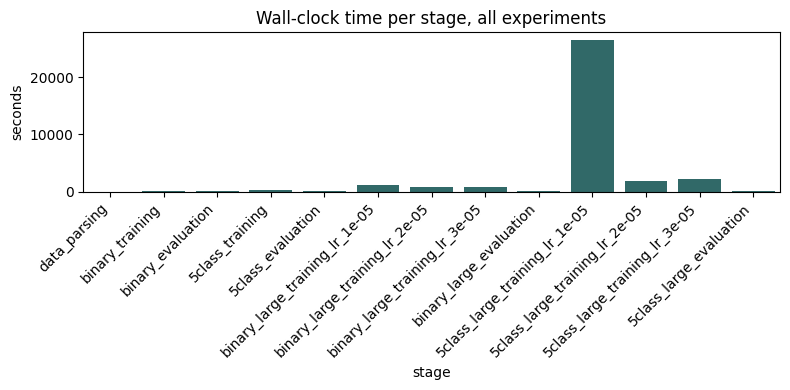

Total wall-clock time across both experiments: 34064.2s


In [47]:
# full four-model comparison and timing summary
timing_df = pd.read_csv(OUTPUT_DIR / "timing_log.csv")

final_comparison = pd.DataFrame({
    "binary (bert-base)": {
        "accuracy": binary_final_metrics.get("eval_accuracy"),
        "f1": binary_final_metrics.get("eval_f1"),
    },
    "binary (bert-large)": {
        "accuracy": eval_result_bin_large.get("eval_accuracy"),
        "f1": eval_result_bin_large.get("eval_f1"),
    },
    "5-class (bert-base)": {
        "accuracy": eval_result_5c.get("eval_accuracy"),
        "f1": eval_result_5c.get("eval_f1"),
        "adjacent_accuracy": adjacent_acc,
    },
    "5-class (bert-large)": {
        "accuracy": eval_result_5c_large.get("eval_accuracy"),
        "f1": eval_result_5c_large.get("eval_f1"),
        "adjacent_accuracy": adjacent_acc_large,
    },
}).T

display(final_comparison)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=timing_df, x="stage", y="elapsed_seconds", ax=ax, color="#287271")
ax.set_ylabel("seconds")
ax.set_title("Wall-clock time per stage, all experiments")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Total wall-clock time across both experiments: {timing_df['elapsed_seconds'].sum():.1f}s")


## Discussion and Limitations

**The larger model helped!**

| | binary | 5-class |
|---|---|---|
| bert-base | 90.1% acc / 0.905 F1 | 48.3% acc / 0.488 macro-F1 / 91.3% adjacent acc |
| bert-large + LR search | 93.5% acc / 0.936 F1 | 53.2% acc / 0.532 macro-F1 / 94.3% adjacent acc |

+3.3 point accuracy gain on binary and a +4.9 point accuracy / +4.3 point macro-F1 gain on 5-class. The 5-class error breakdown backs this up at a finer grain: bert-large made 586 correct predictions vs bert-base's 532, and cut polarity-flip errors (the "actually wrong direction" kind) from 96 down to 63, while adjacent-class errors dropped slightly from 473 to 452. 

**HEAVY LR search** The winning 5-class-large learning rate (1e-05) took about 7.4 hours to train VS ~35 min for the other two. This was very unexpected given same model, same batch size. It won by narrow margin 0.004 macro-F1 over lr=2e-05 (0.532 vs 0.528). 

## References

- Socher, R., Perelygin, A., Wu, J., Chuang, J., Manning, C. D., Ng, A., & Potts, C. (2013). *Recursive Deep Models for Semantic Compositionality Over a Sentiment Treebank.* EMNLP.
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* NAACL.
- Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier.* KDD.
- Lundberg, S. M., & Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions.* NeurIPS.
- Hugging Face model cards: [`bert-base-cased`](https://huggingface.co/bert-base-cased), [`bert-large-cased-whole-word-masking`](https://huggingface.co/bert-large-cased-whole-word-masking).
